**Car Price Prediction**


## Step 1: Data Gathering

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import pandas as pd
path = r"C:\Users\PC\Downloads\car_price_prediction.csv\car_price_prediction.csv"
df=pd.read_csv(path)
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


## Step2 : Data Quality check

In [5]:
len(df)

19237

In [6]:
df.shape

(19237, 18)

In [7]:
def fetch_km(data):
    x=data.split()
    return x[0]

In [8]:
df['Mileage']=df['Mileage'].apply(fetch_km).astype(int)
df['Mileage']

0        186005
1        192000
2        200000
3        168966
4         91901
          ...  
19232    300000
19233    161600
19234    116365
19235     51258
19236    186923
Name: Mileage, Length: 19237, dtype: int64

In [10]:
df.dtypes

ID                    int64
Price                 int64
Levy                    str
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage               int64
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.shape

(18924, 18)

In [17]:
df.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18924 non-null  int64  
 1   Price                     18924 non-null  int64  
 2   Levy                      18924 non-null  str    
 3   Manufacturer              18924 non-null  str    
 4   Model                     18924 non-null  str    
 5   Prod. year                18924 non-null  int64  
 6   Category                  18924 non-null  str    
 7   Leather interior          18924 non-null  str    
 8   Engine volume             18924 non-null  str    
 9   Mileage                   18924 non-null  int64  
 10  Cylinders                 18924 non-null  float64
 11  Gear box type             18924 non-null  str    
 12  Drive wheels              18924 non-null  str    
 13  Doors                     18924 non-null  str    
 14  Wheel                 

## Step3 :  Exploratory data Analysis(EDA)

In [ ]:
#Descriptive Statistics
df.describe().apply(lambda x: x.apply('{:.2f}'.format))

,ID,Price,Prod. year,Mileage,Cylinders,Airbags,Fuel type_CNG,Fuel type_Diesel,Fuel type_Hybrid,Fuel type_Hydrogen,Fuel type_LPG,Fuel type_Petrol,Fuel type_Plug-in Hybrid
count,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00
mean,45575381.03,18587.44,2010.91,1555372.72,4.58,6.57,0.02,0.21,0.19,0.00,0.05,0.53,0.00
std,937546.82,192135.63,5.67,48802205.32,1.20,4.32,0.16,0.41,0.39,0.01,0.21,0.50,0.07
min,20746880.00,1.00,1939.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,45695007.50,5331.00,2009.00,70195.75,4.00,4.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,45771914.50,13172.00,2012.00,126400.00,4.00,6.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
75%,45801742.25,22063.00,2015.00,189119.75,4.00,12.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
max,45816654.00,26307500.00,2020.00,2147483647.00,16.00,16.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


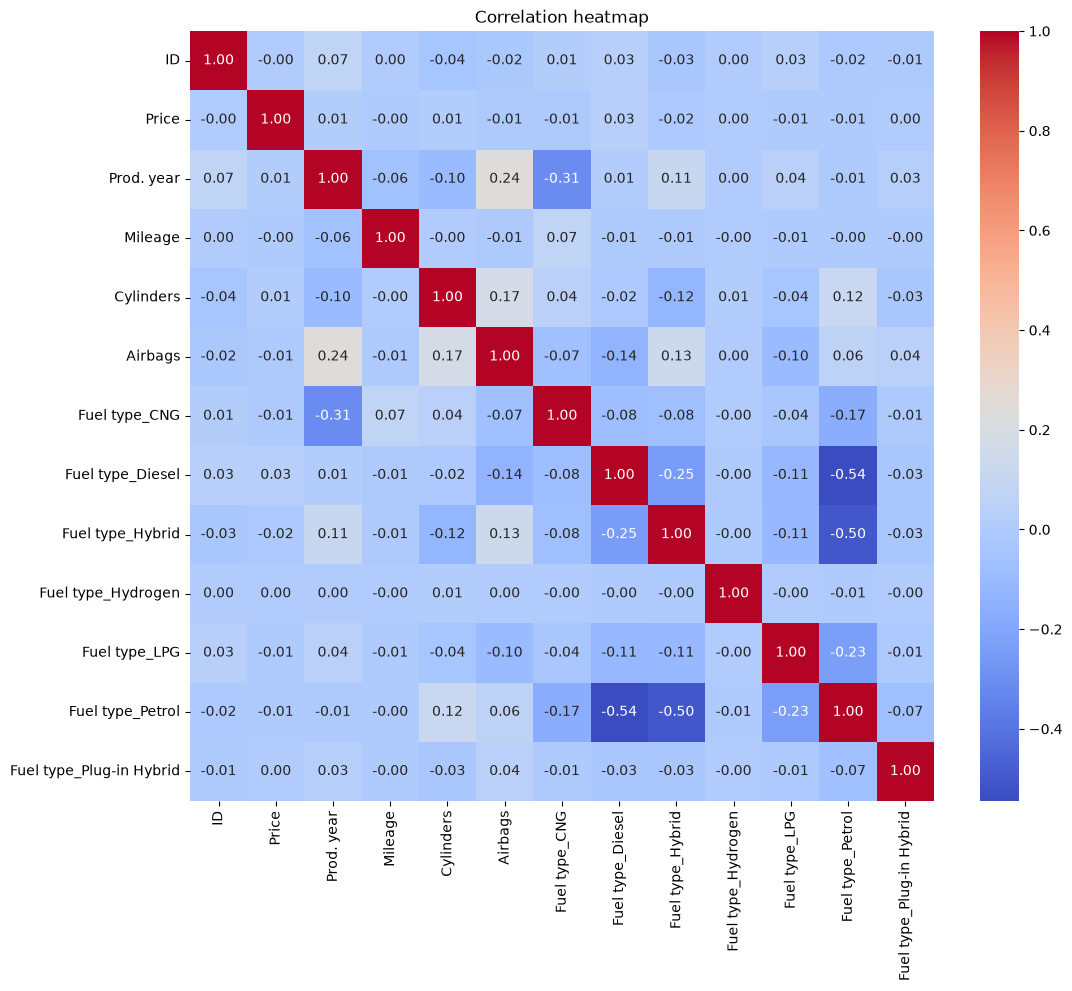

In [18]:
## Correlation 

import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

**Analysis**

    --Most features show weak or negligible linear relationships with each other.
    --No significant relationship is observed among the numerical variables.
    --The features may still have non-linear relationships that correlation cannot capture.

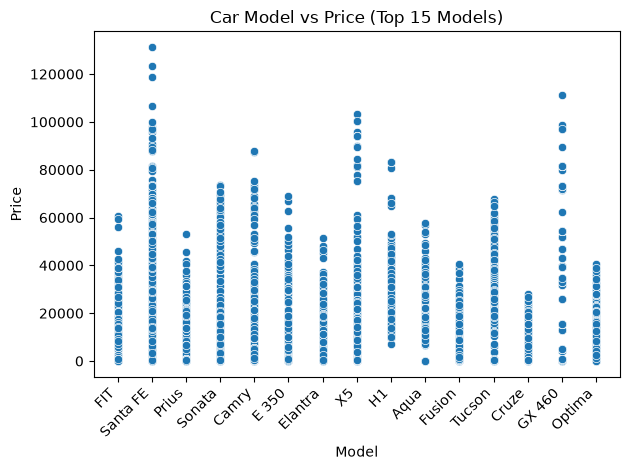

In [19]:
## Scatter plot
import seaborn as sns
import matplotlib.pyplot as plt

top_models = df["Model"].value_counts().head(15).index

data = df[df["Model"].isin(top_models)]

sns.scatterplot(data=data, x="Model", y="Price")

plt.xticks(rotation=45, ha="right")
plt.title("Car Model vs Price (Top 15 Models)")
plt.tight_layout()
plt.show()

**Analysis**

    --Price range: Prices vary widely across car models.
    --Highest prices: Santa Fe, X5, and GX 460 have some high-priced cars.
    --Price variation: Santa Fe, Camry, and X5 show considerable price variation.
    --Outliers: Some unusually high prices need investigation.

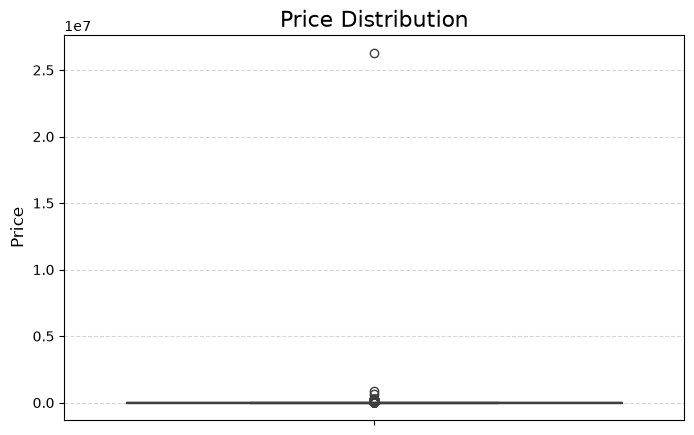

In [21]:
# Boxplot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(y=df["Price"])

plt.title("Price Distribution", fontsize=16)
plt.ylabel("Price", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()


In [41]:
# Clean levy and Engine Value
import pandas as pd
import numpy as np

# Clean Levy
df["Levy"] = df["Levy"].replace("-", np.nan)
df["Levy"] = pd.to_numeric(df["Levy"], errors="coerce")

# Clean Engine volume
df["Engine volume"] = (
    df["Engine volume"]
    .astype("string")
    .str.replace(" Turbo", "", regex=False)
    .str.strip()
)

df["Engine volume"] = pd.to_numeric(
    df["Engine volume"], errors="coerce"
)


df[["Levy", "Engine volume"]].dtypes
df[["Levy", "Engine volume"]].isnull().sum()

Levy             5709
Engine volume       0
dtype: int64

In [ ]:
# Fill missing Levy values with the median
df["Levy"] = df["Levy"].fillna(df["Levy"].median())

# Check missing values
print(df["Levy"].isnull().sum())

0


**Outlier Handling**

In [23]:
cat = list(df.select_dtypes(include='object').columns) 
con = list(df.select_dtypes(include='number').columns)

In [24]:
import numpy as np
out_summary = {}
for col in con:

    q1 = np.percentile(df[col], 25)
    q3 = np.percentile(df[col], 75)

    iqr = q3 - q1 

    minimun = q1 - 1.5 * iqr
    maximum = q3 + 1.5 * iqr

    lower_out = df[col] < minimun
    upper_out = df[col] > maximum

    outliers = df[lower_out | upper_out]

    print("=================")
    print(f"Outliers less than minimum: {df[lower_out]}")
    print(f"Outliers more than maximum: {df[upper_out]}")
    print(f"number of outliers for {col}: {len(outliers)}")
    out_summary[col] = {
        "lower": minimun,
        "upper": maximum,
        "outlier_count": len(outliers),
        "outlier_pct": round(len(outliers)/len(df) * 100, 2)
    }

out_report = pd.DataFrame(out_summary).T
out_report

Outliers less than minimum:              ID  Price    Levy   Manufacturer        Model  Prod. year  \
1      44731507  16621  1018.0      CHEVROLET      Equinox        2011   
15     45465200    549  1079.0         TOYOTA          CHR        2018   
21     45168471  20698   586.0         TOYOTA        Prius        2012   
30     44944581  15681  1288.0  MERCEDES-BENZ         Vito        2007   
36     45369569  51746  1077.0         TOYOTA  CHR Limited        2019   
...         ...    ...     ...            ...          ...         ...   
19176  45511664  14113   531.0        HYUNDAI     Veloster        2012   
19192  45172859  14113     NaN          SCION           xD        2010   
19208  45433278  34811   779.0         TOYOTA        RAV 4        2013   
19223  44571028   8781     NaN          DODGE      Caliber        2008   
19229  39977395     50     NaN         TOYOTA        Prius        2008   

          Category Leather interior  Engine volume  Mileage  ...       Wheel  \
1  

,lower,upper,outlier_count,outlier_pct
ID,4.553491e+07,4.596184e+07,2460.0,13.00
Price,-1.976700e+04,4.716100e+04,1055.0,5.57
Levy,NaN,NaN,0.0,0.00
Prod. year,2.000000e+03,2.024000e+03,962.0,5.08
Engine volume,7.500000e-01,3.550000e+00,1358.0,7.18
Mileage,-1.081902e+05,3.675058e+05,635.0,3.36
Cylinders,4.000000e+00,4.000000e+00,4765.0,25.18
Airbags,-8.000000e+00,2.400000e+01,0.0,0.00
Fuel type_CNG,0.000000e+00,0.000000e+00,469.0,2.48
Fuel type_Diesel,0.000000e+00,0.000000e+00,4001.0,21.14


In [25]:
def handle_outlier(df,col,outlier_percent,mini,maxi):
    lower_index = list(df[df[col]<mini].index) # contains index of all such values which are below min
    upper_index = list(df[df[col]>maxi].index) # contains index of all such values which are above max
    all_ = lower_index + upper_index
    # Perform outlier handling on basis of percentage of outliers present in the data
    df_new = df.copy()
    if outlier_percent<10:
        df_new = df.drop(index=all_) # drops on basis of index we have provided
    else:
        df_new[col] = df[col].clip(mini,maxi)
    return df_new

In [42]:
df2 = df.copy()
for i in con:
    # df.loc[row_name,column_name]
    out_perc = out_report.loc[i,'outlier_pct']
    mini = out_report.loc[i,'lower']
    maxi = out_report.loc[i,'upper']
    df2 = handle_outlier(df2,i,out_perc,mini,maxi=maxi) # positional arguments,keyword arguments
df2

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Engine volume,Mileage,...,Wheel,Color,Airbags,Fuel type_CNG,Fuel type_Diesel,Fuel type_Hybrid,Fuel type_Hydrogen,Fuel type_LPG,Fuel type_Petrol,Fuel type_Plug-in Hybrid
0,4.565440e+07,13328,1399.0,LEXUS,RX 450,2010,Jeep,Yes,3.5,186005,...,Left wheel,Silver,12,0,0,0,0,0,0,0
1,4.553491e+07,16621,1018.0,CHEVROLET,Equinox,2011,Jeep,No,3.0,192000,...,Left wheel,Black,8,0,0,0,0,0,1,0
2,4.577442e+07,8467,NaN,HONDA,FIT,2006,Hatchback,No,1.3,200000,...,Right-hand drive,Black,2,0,0,0,0,0,1,0
3,4.576918e+07,3607,862.0,FORD,Escape,2011,Jeep,Yes,2.5,168966,...,Left wheel,White,0,0,0,0,0,0,0,0
4,4.580926e+07,11726,446.0,HONDA,FIT,2014,Hatchback,Yes,1.3,91901,...,Left wheel,Silver,4,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19231,4.577231e+07,5802,1055.0,MERCEDES-BENZ,E 350,2013,Sedan,Yes,3.5,107800,...,Left wheel,Grey,12,0,0,0,0,0,0,0
19233,4.577886e+07,15681,831.0,HYUNDAI,Sonata,2011,Sedan,Yes,2.4,161600,...,Left wheel,Red,8,0,0,0,0,0,1,0
19234,4.580500e+07,26108,836.0,HYUNDAI,Tucson,2010,Jeep,Yes,2.0,116365,...,Left wheel,Grey,4,0,0,0,0,0,0,0
19235,4.579353e+07,5331,1288.0,CHEVROLET,Captiva,2007,Jeep,Yes,2.0,51258,...,Left wheel,Black,4,0,0,0,0,0,0,0


## Separate X and Y Feature

In [43]:
X = df2.drop(columns=['ID',"Price","Gear box type","Drive wheels","Doors","Wheel"])
Y = df2[['Price']]

In [46]:
for i in ['Manufacturer','Model','Category','Leather interior','Engine volume','Color']:
    print(i,X[i].unique(),sep='\n')

Manufacturer
<StringArray>
[        'LEXUS',     'CHEVROLET',         'HONDA',          'FORD',
       'HYUNDAI',        'TOYOTA', 'MERCEDES-BENZ',       'PORSCHE',
          'JEEP',    'VOLKSWAGEN',          'AUDI',       'RENAULT',
        'NISSAN',           'BMW',        'SUBARU',        'DAEWOO',
           'KIA',     'SSANGYONG',         'MAZDA',           'GMC',
          'FIAT',      'INFINITI',    'MITSUBISHI',    'ALFA ROMEO',
        'SUZUKI',          'OPEL',         'ACURA',       'CITROEN',
          'MINI',         'DODGE',         'ISUZU',           'VAZ',
        'JAGUAR',         'SKODA',       'LINCOLN',         'BUICK',
      'CHRYSLER',      'DAIHATSU',       'PEUGEOT',         'VOLVO',
          'სხვა',         'HAVAL',    'LAND ROVER',      'CADILLAC',
         'SCION',       'MERCURY',          'SEAT',        'LANCIA',
      'MASERATI',          'SAAB',           'GAZ',           'UAZ',
        'HUMMER',       'PONTIAC',        'SATURN',     'GREATWALL']
Length:

In [47]:
cat = list(X.select_dtypes(include='object').columns) 
con = list(X.select_dtypes(include='number').columns)
print(cat)
print(con)

['Manufacturer', 'Model', 'Category', 'Leather interior', 'Color']
['Levy', 'Prod. year', 'Engine volume', 'Mileage', 'Cylinders', 'Airbags', 'Fuel type_CNG', 'Fuel type_Diesel', 'Fuel type_Hybrid', 'Fuel type_Hydrogen', 'Fuel type_LPG', 'Fuel type_Petrol', 'Fuel type_Plug-in Hybrid']


In [48]:
cat_onehot = ['Model', 'Category', 'Leather interior', 'Fuel type', 'Color']
cat_label = ['Manufacturer','Engine volume']

## Step4: Split the Data into Training or Testing

In [54]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat_onehot),
                         ('con',num_pipe,con)]).set_output(transform='pandas')

from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(X,Y,random_state=21,train_size=0.75)

pre.fit(xtrain)

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

# Apply LabelEncoder separately
encoders = {}

for col in cat_label:
    # Impute missing values using training data's most frequent value
    most_frequent = xtrain[col].mode().iloc[0]

    train_col = xtrain[col].fillna(most_frequent).astype(str)
    test_col = xtest[col].fillna(most_frequent).astype(str)

    le = LabelEncoder()
    xtrain_pre[col] = le.fit_transform(train_col)

    # Handle categories in test data that weren't present in training
    mapping = {v: i for i, v in enumerate(le.classes_)}
    xtest_pre[col] = test_col.map(mapping).fillna(-1).astype(int)

    encoders[col] = le

ValueError: Some column names are not columns of the dataframe: {'Fuel type'}

In [ ]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(
    X, Y, train_size=0.75, random_state=42
)

print("X Train:", xtrain.shape)

print("X Test:", xtest.shape)
print("Y Train:", ytrain.shape)
print("Y Test:", ytest.shape)

X Train: (14192, 22)
X Test: (4731, 22)
Y Train: (14192, 1)
Y Test: (4731, 1)


In [ ]:
# Identify Categorical and numerical columns
cat = list(xtrain.select_dtypes(
    include=['object', 'str', 'category']
).columns)

con = list(xtrain.select_dtypes(
    include='number'
).columns)

print("Categorical columns:", cat)
print("Numerical columns:", con)

Categorical columns: ['Manufacturer', 'Model', 'Category', 'Leather interior', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color']
Numerical columns: ['Levy', 'Prod. year', 'Engine volume', 'Mileage', 'Cylinders', 'Airbags', 'Fuel type_CNG', 'Fuel type_Diesel', 'Fuel type_Hybrid', 'Fuel type_Hydrogen', 'Fuel type_LPG', 'Fuel type_Petrol', 'Fuel type_Plug-in Hybrid']


## Step5: Data preprocessing and Data Cleaning

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical pipeline
num_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)

# Categorical pipeline
cat_pipe = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore', sparse_output=False)
)

# Combine both pipelines
pre = ColumnTransformer([
    ('cat', cat_pipe, cat),
    ('con', num_pipe, con)
]).set_output(transform='pandas')

# Fit and transform training data
pre.fit(xtrain)

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

print("Training data:", xtrain_pre.shape)
print("Testing data:", xtest_pre.shape)


Training data: (14192, 1445)
Testing data: (4731, 1445)


In [ ]:
pre.fit(xtrain)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [ ]:
xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

In [ ]:
print(xtrain_pre.shape)
print(xtest_pre.shape)

(14192, 1445)
(4731, 1445)


## Step 6: Model Building

**Algorithm Evolution**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Create models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=21),
    'Random Forest': RandomForestRegressor(random_state=21),
    'Gradient Boosting': GradientBoostingRegressor(random_state=21),
    'XGBoost': XGBRegressor(random_state=21)
}

results = {}

# Train and evaluate models
for name, model in models.items():

    model.fit(xtrain_pre, np.ravel(ytrain))

    ypred = model.predict(xtest_pre)

    r2 = r2_score(np.ravel(ytest), ypred)
    mae = mean_absolute_error(np.ravel(ytest), ypred)
    rmse = np.sqrt(mean_squared_error(np.ravel(ytest), ypred))

    results[name] = {
        'R2 Score': r2,
        'MAE': mae,
        'RMSE': rmse
    }

# Display results
results_df = pd.DataFrame(results).T

print(results_df.round(2))

## Hyperparameter Tunning

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

rf = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=2,
    random_state=21,
    n_jobs=-1
)

rf.fit(xtrain_pre, ytrain.values.ravel())

y_pred = rf.predict(xtest_pre)

print("R2 Score:", r2_score(ytest, y_pred))
print("MAE:", mean_absolute_error(ytest, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(ytest, y_pred)))

R2 Score: 0.6540854043500859
MAE: 5018.742918938421
RMSE: 10685.027934469219


In [ ]:
print(models.keys())

dict_keys(['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost'])


In [ ]:
best_model = models['Random Forest']

In [ ]:
from sklearn.ensemble import RandomForestRegressor

best_model = RandomForestRegressor(random_state=21, n_jobs=1)

best_model.fit(xtrain_pre, ytrain.values.ravel())

In [ ]:
ytest_pred = best_model.predict(xtest_pre)

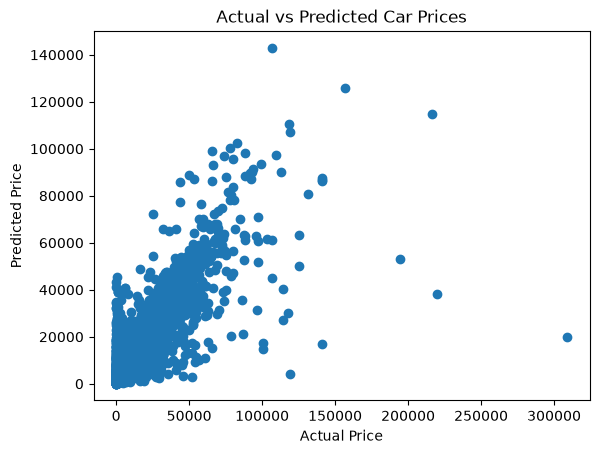

In [ ]:
## Actual vs Predicted Plot

import matplotlib.pyplot as plt

plt.scatter(ytest, ytest_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

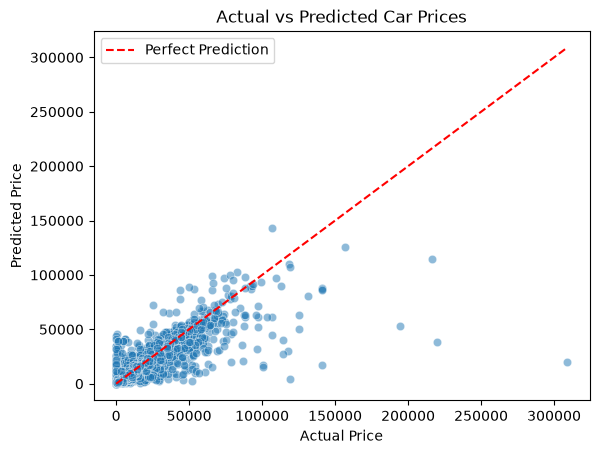

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x=ytest.values.ravel(), y=ytest_pred, alpha=0.5)

plt.plot(
    [0, ytest.max().iloc[0]],
    [0, ytest.max().iloc[0]],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.legend()
plt.show()

## Analysis

      -- Most points are concentrated near the bottom-left.
      --The model performs better for some lower-priced cars.
      --Expensive cars are often underpredicted.
      --The model struggles to predict some expensive cars.

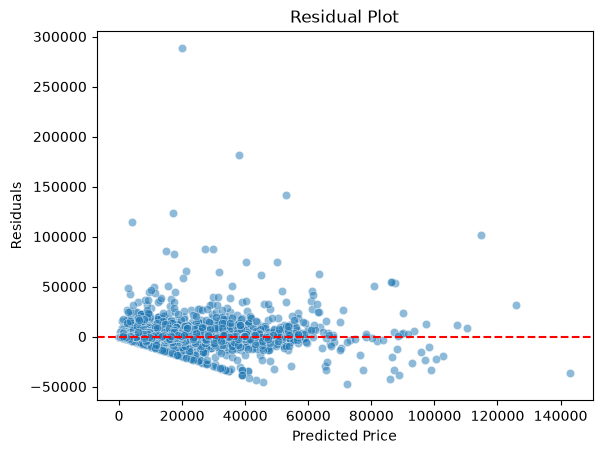

In [ ]:
## Residual plot(To identify errors)
import seaborn as sns
import matplotlib.pyplot as plt

residuals = ytest.values.ravel() - ytest_pred

sns.scatterplot(x=ytest_pred, y=residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

## Analysis

    --Points near zero indicate smaller prediction errors.
    --Positive residuals mean the model underpredicts prices.
    --Negative residuals mean the model overpredicts prices.
    --Some points have very large errors, especially for certain expensive cars

## Step 6: Final Deliverables

    --Data Gathering: Collected used-car data.
    --Data Cleaning: Handled missing values and corrected data types.
    --EDA: Analyzed price distributions and investigated outliers.
    --Feature Selection: Selected car features as inputs and Price as the target.
    --Preprocessing: Encoded categorical features and scaled numerical features.
    --Train-Test Split: Divided data into training and testing sets.
    --Model Training: Trained and compared five regression models.
    --Model Evaluation: Evaluated models using R², MAE, and RMSE.
    --Best Model: Random Forest achieved an R² score of 0.68.

In [ ]:
import joblib

# Save the trained model
joblib.dump(best_model, "car_price_model.joblib")

# Save the preprocessing pipeline
joblib.dump(pre, "preprocessor.joblib")

print("Model and preprocessor saved successfully!")


Model and preprocessor saved successfully!
